# 05 · The Nyquist criterion

The Nyquist criterion decides closed-loop stability from the open-loop frequency response - a quantity one can
measure - and it works for unstable plants, for delays, and for anything without a rational transfer function.
It rests on Cauchy's argument principle: as s travels once around a contour enclosing the right half-plane,
the number of times L(s) encircles −1 equals the number of closed-loop poles minus the number of open-loop
poles inside. This notebook builds the contour, counts the encirclements, treats poles on the imaginary axis,
and shows the criterion at work on a plant that is only stable with feedback.

**What you will learn**
- state the Nyquist criterion and count encirclements on a computed contour
- handle poles on the imaginary axis by indentation
- read gain and phase margins and the closest approach to -1 from the plot
- apply the criterion to loops with delays and unstable plants

**Before you start:** notebooks 02 and 03  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, frequency as fr, stability as st, polynomials as pl, response as rs
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Encirclements of −1: Z = N + P

1/(s(s+1)(s+2)): stable loop            : Z = 0 closed-loop RHP poles; from the characteristic polynomial: 0
10/(s(s+1)(s+2)): too much gain         : Z = 2 closed-loop RHP poles; from the characteristic polynomial: 2
2/(s - 1): unstable plant, stabilised   : Z = 0 closed-loop RHP poles; from the characteristic polynomial: 0


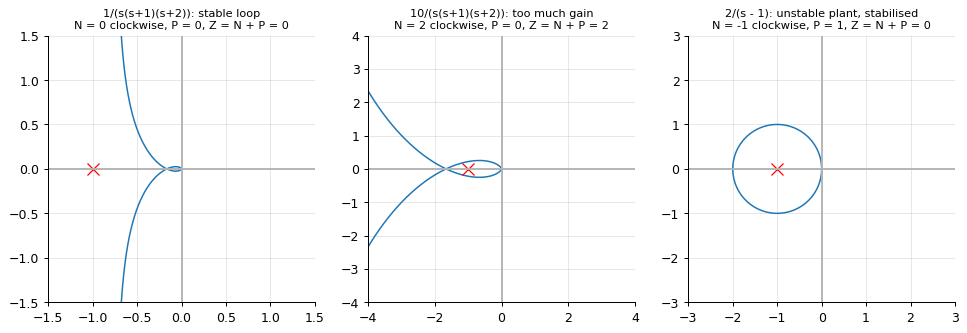

In [2]:
def nyquist_figure(L, ax, lim=3.0, title=""):
    r = st.nyquist_criterion(L)
    Ls = r["L"]
    ax.plot(Ls.real, Ls.imag, lw=1.2); ax.plot(-1, 0, "rx", ms=9)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.axhline(0, color="0.7"); ax.axvline(0, color="0.7")
    ax.set_title(f"{title}\nN = {r['N_clockwise']} clockwise, P = {r['P']}, Z = N + P = {r['Z']}", fontsize=9)
    return r
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (L, lim, name) in zip(axes, ((sy.tf([1.0], [1.0, 3.0, 2.0, 0.0]), 1.5, "1/(s(s+1)(s+2)): stable loop"), (sy.tf([10.0], [1.0, 3.0, 2.0, 0.0]), 4.0, "10/(s(s+1)(s+2)): too much gain"), (sy.tf([2.0], [1.0, -1.0]), 3.0, "2/(s - 1): unstable plant, stabilised"))):
    r = nyquist_figure(L, ax, lim, name)
    print(f"{name:<40}: Z = {r['Z']} closed-loop RHP poles; from the characteristic polynomial: {r['closed_loop_rhp_poles']}")
plt.show()

Three loops, three verdicts. The stable loop with K = 1 leaves −1 outside the curve (N = 0, P = 0, Z = 0); with
K = 10 the curve swings round −1 twice clockwise (Z = 2: two unstable closed-loop poles, exactly those the
characteristic polynomial has); and the unstable plant 2/(s − 1) is stabilised by the loop: its curve encircles
−1 once *counterclockwise* (N = −1) which cancels the open-loop unstable pole (P = 1) to give Z = 0. The last
case is the one no Bode-plot rule of thumb handles, and the reason the criterion is worth its contour.

## The contour and the indentation around poles on the axis

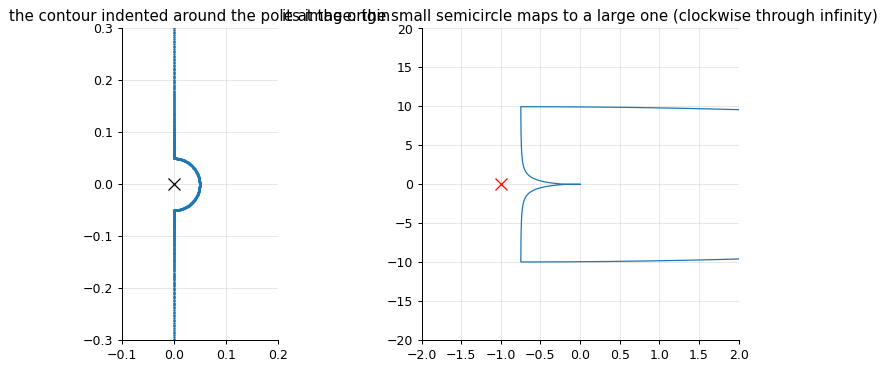

with eps = 0.05 the image of the indentation reaches |L| = 10; the count is unaffected: N = 0, Z = 0


In [3]:
L = sy.tf([1.0], [1.0, 3.0, 2.0, 0.0])
r = st.nyquist_criterion(L, eps=0.05, n=4000)
s = r["contour"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].plot(s.real, s.imag, ".", ms=2); axes[0].plot(0, 0, "kx", ms=9); axes[0].set_xlim(-0.1, 0.2); axes[0].set_ylim(-0.3, 0.3); axes[0].set_aspect("equal"); axes[0].set_title("the contour indented around the pole at the origin")
Ls = r["L"]
axes[1].plot(Ls.real, Ls.imag, lw=1); axes[1].plot(-1, 0, "rx", ms=9); axes[1].set_xlim(-2, 2); axes[1].set_ylim(-20, 20); axes[1].set_title("its image: the small semicircle maps to a large one (clockwise through infinity)")
plt.show()
print(f"with eps = 0.05 the image of the indentation reaches |L| = {np.max(np.abs(Ls)):.0f}; the count is unaffected: N = {r['N_clockwise']}, Z = {r['Z']}")

A pole on the imaginary axis - the integrator here - lies on the contour, where L is infinite; the contour
detours around it by a small semicircle into the right half-plane (so the pole is excluded from P), and L maps
that semicircle to a large arc at infinity that closes the curve. The library builds this contour explicitly,
logarithmically dense near the origin so that nothing is missed, and counts the phase change of 1 + L along
it. Poles at other points of the axis get the same treatment; closed-loop poles *on* the axis make the
criterion meaningless (1 + L vanishes on the contour) and are flagged as marginal.

## From the criterion to the margins

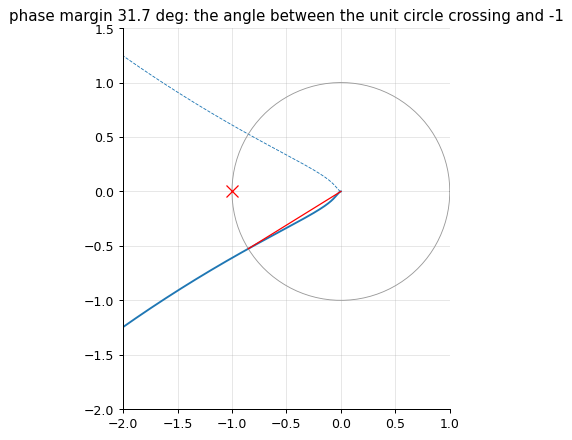

closest approach to -1: 0.533 (= 1/Ms, the sensitivity peak 1.88); gain margin inf, phase margin 31.7 deg


In [4]:
L = sy.zpk([-10.0], [0.0, -1.0, -50.0], 100.0)
w = np.logspace(-2, 3, 3000)
_, Lj = fr.nyquist(L, w)
m = fr.margins(L)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(Lj.real, Lj.imag); ax.plot(Lj.real, -Lj.imag, "--", color="C0", lw=0.7)
th = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(th), np.sin(th), "0.6", lw=0.7)
Lg = fr.freqresp(L, m["w_gc"]); ax.plot([0, Lg.real], [0, Lg.imag], "r-", lw=1); ax.plot(-1, 0, "rx", ms=9)
ax.set_xlim(-2, 1); ax.set_ylim(-2, 1.5); ax.set_aspect("equal"); ax.set_title(f"phase margin {m['phase_margin']:.1f} deg: the angle between the unit circle crossing and -1"); plt.show()
dist = np.min(np.abs(1 + Lj))
print(f"closest approach to -1: {dist:.3f} (= 1/Ms, the sensitivity peak {1 / dist:.2f}); gain margin {m['gain_margin']}, phase margin {m['phase_margin']:.1f} deg")

On the Nyquist plot the margins are distances from −1: the gain margin along the negative real axis, the phase
margin along the unit circle. The single number that captures both is the closest approach of the curve to
−1, which is 1/M_s with M_s the peak of the sensitivity function (notebook 14): this loop never crosses the
real axis left of the origin (infinite gain margin) but comes within 0.5 of −1, which is why its step response
rings. Margins are shorthand for that distance, and can mislead when the curve approaches −1 obliquely.

## A delay: where the criterion earns its keep

In [5]:
P = sy.tf([1.0], [1.0, 1.0])
w = np.logspace(-2, 2, 4000)
for Td in (0.0, 0.5, 1.0, 2.0):
    K = 2.0
    Lj = K * fr.freqresp(P, w, delay=Td)
    phase = np.degrees(np.unwrap(np.angle(Lj)))
    m = fr.margins(sy.tf([K], [1.0, 1.0]), delay=Td)
    print(f"delay {Td:.1f} s: gain margin {m['gain_margin']:.3f}, phase margin {m['phase_margin']:.1f} deg, closest approach to -1: {np.min(np.abs(1 + Lj)):.3f}")
Td = 2.0
print(f"\nwith a 2 s delay the loop K/(s+1) e^(-2s) is unstable at K = 2: the curve spirals around -1; the maximum stable gain is {fr.margins(sy.tf([1.0], [1.0, 1.0]), delay=2.0)['gain_margin']:.3f}")
t_sim = np.linspace(0, 30, 3001)

delay 0.0 s: gain margin inf, phase margin 120.0 deg, closest approach to -1: 1.000
delay 0.5 s: gain margin 1.903, phase margin 70.4 deg, closest approach to -1: 0.450
delay 1.0 s: gain margin 1.131, phase margin 20.8 deg, closest approach to -1: 0.111
delay 2.0 s: gain margin 0.760, phase margin -78.5 deg, closest approach to -1: 0.308



with a 2 s delay the loop K/(s+1) e^(-2s) is unstable at K = 2: the curve spirals around -1; the maximum stable gain is 1.520


A time delay e^{−sT} has no poles or zeros and no rational transfer function, yet its frequency response - unit
magnitude, phase −ωT - is exact, and the Nyquist curve of K e^{−sT}/(s+1) spirals inward through every phase.
The criterion handles it directly: the gain margin shrinks as the delay grows (to 1.52 at T = 2 s) until K = 2
no longer stabilises the loop. Delays are the commonest reason control loops are slower than their plants
seem to allow, and notebook 14 quantifies the limit; the Padé approximation (`frequency.pade`) brings them
into the rational world when a state-space model is needed.

## Inside the algorithm: counting encirclements by the winding of 1 + L

In [6]:
r = st.nyquist_criterion(sy.tf([10.0], [1.0, 3.0, 2.0, 0.0]))
phase = np.unwrap(np.angle(1 + r["L"]))
print(f"total phase change of 1 + L along the contour: {np.degrees(phase[-1] - phase[0]):.1f} degrees = {(phase[-1] - phase[0]) / (2 * np.pi):.2f} turns (counterclockwise positive) -> N clockwise = {r['N_clockwise']}")

total phase change of 1 + L along the contour: -720.0 degrees = -2.00 turns (counterclockwise positive) -> N clockwise = 2


## Exercises
1. Apply the criterion to L = K/(s - 1)^2 for K = 0.5, 2 and 5 and compare with the closed-loop poles. Is there any K that stabilises it? Then add a zero, L = K (s + 1)/(s - 1)^2, and find the stabilising range.
2. For P = 1/(s + 1)^3 with proportional gain K, find from the Nyquist curve the gain at which the loop goes unstable, and compare with the Routh limit and with the ultimate gain used in notebook 06.
3. **Implement it yourself:** build the Nyquist contour for L = 1/(s^2 (s + 1)) with the indentation around the double pole, evaluate L along it and count the encirclements of -1; compare with `stability.nyquist_criterion` and with the closed-loop poles.